# 02. Статистический анализ прогнозных оценок


In [1]:
knitr::opts_chunk$set(
  echo = FALSE,
  message = FALSE,
  warning = FALSE,
  fig.align = "center",
  fig.width = 9,
  fig.height = 5
)


# О документе

Отчёт смотрит, как прогнозные оценки качества связаны друг с другом, с индексами и с категориальными признаками изделия.

| | |
|---|---|
| **Данные** | `data/scores.csv` |
| **Цель** | Корреляции Кендалла и тесты связи «число ↔ категория» |
| **Оценки** | `output`, `related`, `frequency`, `yield`, `volume`, `defect` |
| **Индексы** | `overall_index`, `process_index`, `product_index` |


In [2]:
library(tidyr)
library(dplyr)
library(ggplot2)



Attaching package: ‘dplyr’



The following objects are masked from ‘package:stats’:

    filter, lag



The following objects are masked from ‘package:base’:

    intersect, setdiff, setequal, union



In [3]:
indexes <- c("overall_index", "process_index", "product_index")
estimates <- c("output", "related", "frequency", "yield", "volume", "defect")
cat_columns <- c("type", "year", "series", "class", "plant", "mark", "method", "certified")
estimated_columns <- c(estimates, indexes)


# 1. Введение

Прогнозные оценки качества — результат статистической модели по производственным показателям. Их анализ показывает, насколько согласованы оценки, собранные из них индексы и базовые характеристики изделий.

# 2. Данные

Берём рассчитанные оценки и индексы, убираем пропуски: для этого исследования они не нужны.


In [4]:
scores <- read.csv("data/scores.csv") %>%
  filter(
    !is.na(overall_index),
    !is.na(process_index),
    !is.na(product_index),
    !is.na(series)
  ) %>%
  filter(if_all(all_of(estimated_columns), ~ !is.na(.))) %>%
  mutate(across(all_of(cat_columns), as.character)) %>%
  mutate(across(all_of(cat_columns), ~ replace_na(., "Неизвестно"))) %>%
  mutate(across(all_of(cat_columns), as.factor))


После фильтрации в выборке **`r length(unique(scores$item_id))`** изделий.

# 3. Корреляция между числовыми переменными

Алгоритм:

1. Проверяем нормальность тестом Шапиро–Уилка.  
   H0: распределение отличается от нормального при p ≤ 0.05; H1: нормальное при p > 0.05.
2. Если распределение ненормальное — дополнительно смотрим выбросы z-тестом.
3. Нормальное → Пирсон; ненормальное без выбросов → Спирмен; ненормальное с выбросами → Кендалл.

Здесь распределение ненормальное, выбросы есть, поэтому считаем корреляцию Кендалла.


In [5]:
corr_df <- function(df, features) {
  as.data.frame(cor(df[features], method = "kendall")) %>%
    mutate(column_from = rownames(.)) %>%
    pivot_longer(cols = all_of(features), names_to = "column_to", values_to = "correlation") %>%
    filter(column_from != column_to) %>%
    filter(column_from <= column_to) %>%
    mutate(
      t = case_when(
        column_from %in% indexes & column_to %in% indexes ~ 1,
        column_from %in% estimates & column_to %in% estimates ~ 2,
        TRUE ~ 3
      )
    ) %>%
    arrange(desc(abs(correlation)))
}


In [6]:
correlation <- corr_df(scores, estimated_columns)


Тепловая карта всех пар:


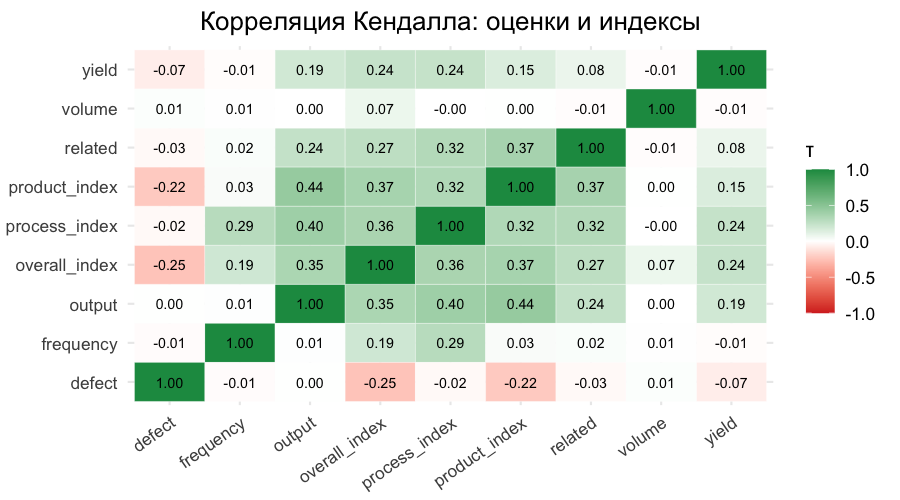

In [7]:
corr_heat <- as.data.frame(cor(scores[estimated_columns], method = "kendall")) %>%
  mutate(column_from = rownames(.)) %>%
  pivot_longer(cols = all_of(estimated_columns), names_to = "column_to", values_to = "correlation")
ggplot(corr_heat, aes(column_from, column_to, fill = correlation)) +
  geom_tile(color = "white") +
  geom_text(aes(label = sprintf("%.2f", correlation)), size = 3) +
  scale_fill_gradient2(low = "#d73027", mid = "white", high = "#1a9850", midpoint = 0, limits = c(-1, 1)) +
  labs(title = "Корреляция Кендалла: оценки и индексы", x = NULL, y = NULL, fill = "τ") +
  theme_minimal(base_size = 13) +
  theme(axis.text.x = element_text(angle = 35, hjust = 1), plot.title = element_text(hjust = 0.5))


## 3.1. Корреляция между индексами

Корреляция Кендалла для сводного, процессного и продуктового индексов:


In [8]:
knitr::kable(
  correlation %>% filter(t == 1) %>% dplyr::select(column_from, column_to, correlation),
  digits = 3
)




|column_from   |column_to     | correlation|
|:-------------|:-------------|-----------:|
|overall_index |product_index |       0.367|
|overall_index |process_index |       0.355|
|process_index |product_index |       0.324|


Между индексами корреляция высокая — они связаны.

## 3.2. Корреляция между индексами и оценками

Индексы: сводный (`overall_index`), процессный (`process_index`), продуктовый (`product_index`).  
Оценки: производительность (`output`), сопутствующий выпуск (`related`), выход годного (`yield`), частота выпуска (`frequency`), объём партии (`volume`), доля брака (`defect`).


In [9]:
knitr::kable(
  correlation %>% filter(t == 3) %>% dplyr::select(column_from, column_to, correlation),
  digits = 3
)




|column_from   |column_to     | correlation|
|:-------------|:-------------|-----------:|
|output        |product_index |       0.441|
|output        |process_index |       0.401|
|product_index |related       |       0.370|
|output        |overall_index |       0.349|
|process_index |related       |       0.315|
|frequency     |process_index |       0.295|
|overall_index |related       |       0.271|
|defect        |overall_index |      -0.248|
|process_index |yield         |       0.237|
|overall_index |yield         |       0.235|
|defect        |product_index |      -0.225|
|frequency     |overall_index |       0.194|
|product_index |yield         |       0.146|
|overall_index |volume        |       0.073|
|frequency     |product_index |       0.026|
|defect        |process_index |      -0.024|
|product_index |volume        |       0.003|
|process_index |volume        |      -0.001|


В большинстве пар связь есть.

## 3.3. Корреляция между оценками


In [10]:
knitr::kable(
  correlation %>% filter(t == 2) %>% dplyr::select(column_from, column_to, correlation),
  digits = 3
)




|column_from |column_to | correlation|
|:-----------|:---------|-----------:|
|output      |related   |       0.244|
|output      |yield     |       0.190|
|related     |yield     |       0.080|
|defect      |yield     |      -0.073|
|defect      |related   |      -0.025|
|frequency   |related   |       0.022|
|defect      |frequency |      -0.013|
|defect      |volume    |       0.013|
|frequency   |yield     |      -0.011|
|volume      |yield     |      -0.010|
|related     |volume    |      -0.008|
|frequency   |output    |       0.008|
|frequency   |volume    |       0.007|
|defect      |output    |       0.004|
|output      |volume    |       0.002|


Связь между оценками слабее, чем между индексами, но в большинстве пар она тоже есть.

# 4. Связь числа и категории

Алгоритм:

1. Нормальность числовой переменной — Шапиро–Уилк.
2. Если нормальное — ANOVA; если нет — Краскел–Уоллис.  
   Чем выше статистика и ниже p, тем сильнее связь. При p < 0.05 связь считаем значимой.


In [11]:
shapiro_sample <- function(x) {
  x <- x[!is.na(x)]
  if (length(x) > 5000) x <- sample(x, 5000)
  x
}

сategory_dependency <- function(dataset, var_1, var_2) {
  x <- shapiro_sample(dataset[[var_1]])
  if (shapiro.test(x)$p.value < 0.05) {
    kt <- kruskal.test(dataset[[var_1]] ~ dataset[[var_2]], data = dataset)
    return(c(var_2, as.numeric(kt$statistic), as.numeric(kt$p.value)))
  }
  result <- aov(dataset[[var_1]] ~ dataset[[var_2]], data = dataset)
  c(var_2, summary.aov(result)[[1]][["F value"]][1], summary.aov(result)[[1]][["Pr(>F)"]][1])
}

category_dependency_df <- function(dataset, vector, col) {
  as.data.frame(t(sapply(vector, function(var) сategory_dependency(dataset, col, var)))) %>%
    mutate(column_to = col) %>%
    dplyr::select(V1, column_to, V2, V3) %>%
    rename(column_from = V1, statistic = V2, p_value = V3) %>%
    `rownames<-`(NULL) %>%
    mutate(
      statistic = as.numeric(statistic),
      p_value = as.numeric(p_value),
      is_significance = p_value < 0.05
    ) %>%
    arrange(p_value)
}


## 4.1. Индексы и категории

Категории: тип (`type`), класс (`class`), год выпуска (`year`), серия (`series`), площадка (`plant`), марка (`mark`), метод (`method`), сертификация (`certified`).




|column_from |column_to     | statistic| p_value|is_significance |
|:-----------|:-------------|---------:|-------:|:---------------|
|method      |overall_index |   46.4405|  0.0000|TRUE            |
|year        |overall_index |    5.4787|  0.0000|TRUE            |
|series      |overall_index |    2.7765|  0.0003|TRUE            |
|certified   |overall_index |    3.1159|  0.0776|FALSE           |
|plant       |overall_index |    1.9251|  0.0869|FALSE           |
|class       |overall_index |    0.8647|  0.4843|FALSE           |
|mark        |overall_index |    0.8252|  0.5089|FALSE           |
|type        |overall_index |    0.3299|  0.5657|FALSE           |
|year        |process_index |    6.6128|  0.0000|TRUE            |
|series      |process_index |    2.7029|  0.0004|TRUE            |
|method      |process_index |    7.4569|  0.0006|TRUE            |
|class       |process_index |    2.3350|  0.0534|FALSE           |
|plant       |process_index |    1.1932|  0.3098|FALSE      

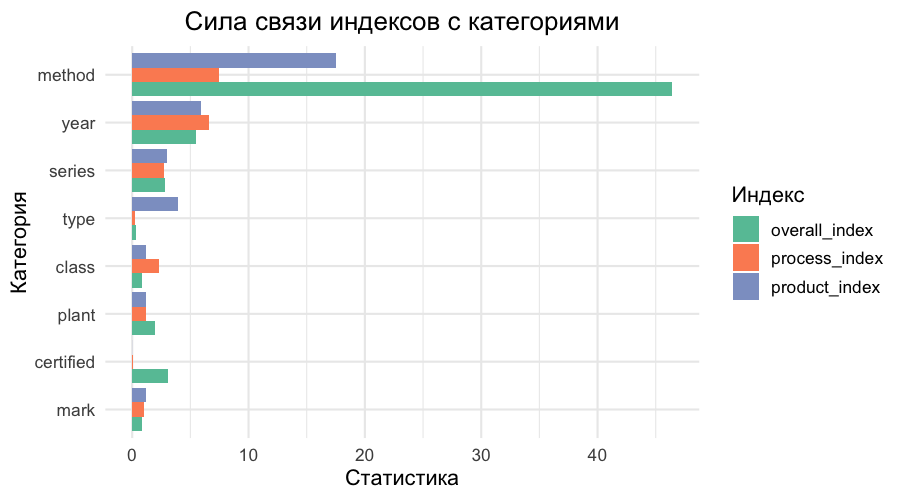

In [12]:
knitr::kable(
  bind_rows(lapply(indexes, function(x) category_dependency_df(scores, cat_columns, x))),
  digits = 4
)
dep_idx <- bind_rows(lapply(indexes, function(x) category_dependency_df(scores, cat_columns, x)))
ggplot(dep_idx, aes(x = reorder(column_from, statistic), y = statistic, fill = column_to)) +
  geom_col(position = "dodge") +
  coord_flip() +
  scale_fill_brewer(palette = "Set2") +
  labs(title = "Сила связи индексов с категориями", x = "Категория", y = "Статистика", fill = "Индекс") +
  theme_minimal(base_size = 13) +
  theme(plot.title = element_text(hjust = 0.5))


Распределения ненормальные, поэтому везде Краскел–Уоллис. Почти все связи значимы. По величине статистики обычно лидируют серия, площадка и марка.

## 4.2. Оценки и категории




|column_from |column_to | statistic| p_value|is_significance |
|:-----------|:---------|---------:|-------:|:---------------|
|series      |output    |    7.6063|  0.0000|TRUE            |
|type        |output    |    9.9720|  0.0016|TRUE            |
|year        |output    |    2.6081|  0.0018|TRUE            |
|class       |output    |    1.6699|  0.1541|FALSE           |
|plant       |output    |    1.6005|  0.1565|FALSE           |
|certified   |output    |    0.1276|  0.7210|FALSE           |
|mark        |output    |    0.4637|  0.7624|FALSE           |
|method      |output    |    0.1285|  0.8794|FALSE           |
|year        |related   |    7.9865|  0.0000|TRUE            |
|type        |related   |    3.3437|  0.0676|FALSE           |
|series      |related   |    1.3516|  0.1626|FALSE           |
|mark        |related   |    1.4782|  0.2061|FALSE           |
|class       |related   |    1.3937|  0.2335|FALSE           |
|method      |related   |    1.3555|  0.2580|FALSE   

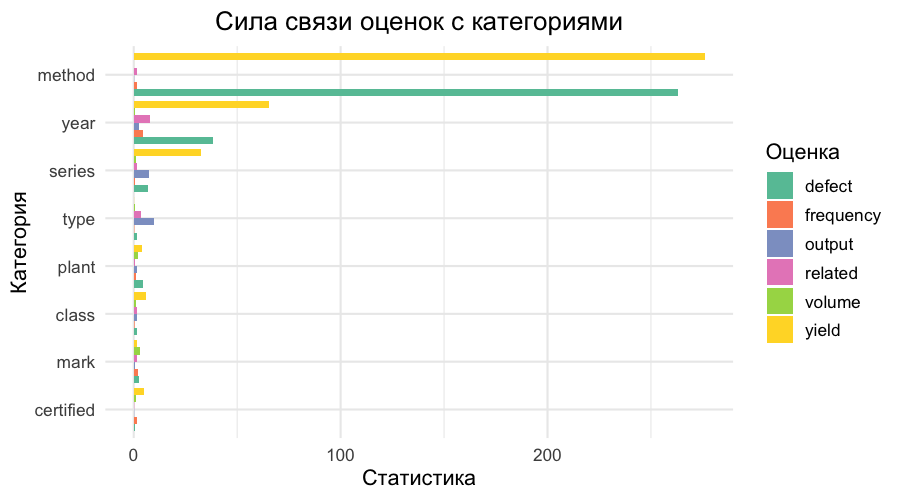

In [13]:
knitr::kable(
  bind_rows(lapply(estimates, function(x) category_dependency_df(scores, cat_columns, x))),
  digits = 4
)
dep_est <- bind_rows(lapply(estimates, function(x) category_dependency_df(scores, cat_columns, x)))
ggplot(dep_est, aes(x = reorder(column_from, statistic), y = statistic, fill = column_to)) +
  geom_col(position = "dodge") +
  coord_flip() +
  scale_fill_brewer(palette = "Set2") +
  labs(title = "Сила связи оценок с категориями", x = "Категория", y = "Статистика", fill = "Оценка") +
  theme_minimal(base_size = 13) +
  theme(plot.title = element_text(hjust = 0.5))


Картина та же: серия, площадка и марка чаще всего сильнее остальных категорий.

# 5. Заключение

Между индексами, между индексами и оценками и между самими оценками есть зависимость — иногда сильная. Одни показатели заметно влияют на другие.
